# 8. Spelling-aware WER

A second metric next to the unchanged WER: edits the rules type as spelling convention or segmentation (দু পাশে /
দুপাশে), the two types the annotators confirmed as spelling only, are not counted. Same normalizer and alignment.

In [1]:
from nbutil import *
import pandas as pd

In [2]:
import importlib.util
spec = importlib.util.spec_from_file_location("saw", ROOT / "analysis/spelling_aware_wer.py")
saw = importlib.util.module_from_spec(spec); spec.loader.exec_module(saw)
source(saw.per_clip)

def per_clip(path: str) -> pd.DataFrame:
    rows = []
    for line in open(Path(path) / "predictions.jsonl", encoding="utf-8"):
        r = json.loads(line)
        ref, hyp = normalize_bangla_text(r["ref"]).split(), normalize_bangla_text(r["hyp"]).split()
        edits = classify_alignment(ref, hyp)
        assert len(edits) == Levenshtein.distance(ref, hyp), r["utt_id"]
        types = [e["type"] for e in edits]
        spell = sum(t in SPELLING for t in types)
        rows.append({"utt_id": r["utt_id"], "group": str(r["group"]), "words": len(ref), "edits": len(edits),
                     "sa_edits": len(edits) - spell, "sa_num_edits": len(edits) - spell - types.count("number")})
    return pd.DataFrame(rows)



In [3]:
S = pd.read_csv(ROOT / "results/spelling_aware/summary.csv")
for col in ("wer", "sa_wer"):
    t = (100 * S.pivot(index="system", columns="set", values=col)[list(SETS)]).rename(columns=SETS)
    t["average"] = t.mean(axis=1)
    display(Markdown(f"**{'standard WER' if col == 'wer' else 'spelling-aware WER'}**")); display(t.round(2))

**standard WER**

set,DL Sprint eval,FLEURS,Common Voice,Kathbath,average
system,,,,,
Final model,11.18,15.60,10.13,10.28,11.80
Hishab conformer large,21.18,14.24,7.72,8.32,12.87
IndicConformer CTC,28.13,16.03,14.04,11.20,17.35
IndicConformer RNN-T,31.02,15.72,13.20,10.64,17.65
"M1 (DL Sprint, 60 h)",11.34,18.34,12.80,13.48,13.99
M5 (10 h x 4),13.84,16.85,10.97,11.06,13.18
M5-300 (300 h),11.49,15.35,10.21,10.07,11.78
M5-full (156 h),11.50,16.23,10.35,10.07,12.04
Team Villagers,13.87,19.57,15.62,14.65,15.93


**spelling-aware WER**

set,DL Sprint eval,FLEURS,Common Voice,Kathbath,average
system,,,,,
Final model,8.82,10.89,6.61,5.87,8.04
Hishab conformer large,15.40,10.15,3.87,4.80,8.56
IndicConformer CTC,23.79,12.10,9.77,6.97,13.16
IndicConformer RNN-T,26.44,11.39,8.76,6.18,13.19
"M1 (DL Sprint, 60 h)",9.16,12.77,8.80,7.94,9.67
M5 (10 h x 4),10.92,11.98,7.31,6.67,9.22
M5-300 (300 h),9.07,10.87,6.72,5.90,8.14
M5-full (156 h),9.18,11.30,6.85,6.01,8.34
Team Villagers,11.38,14.13,11.57,9.13,11.55


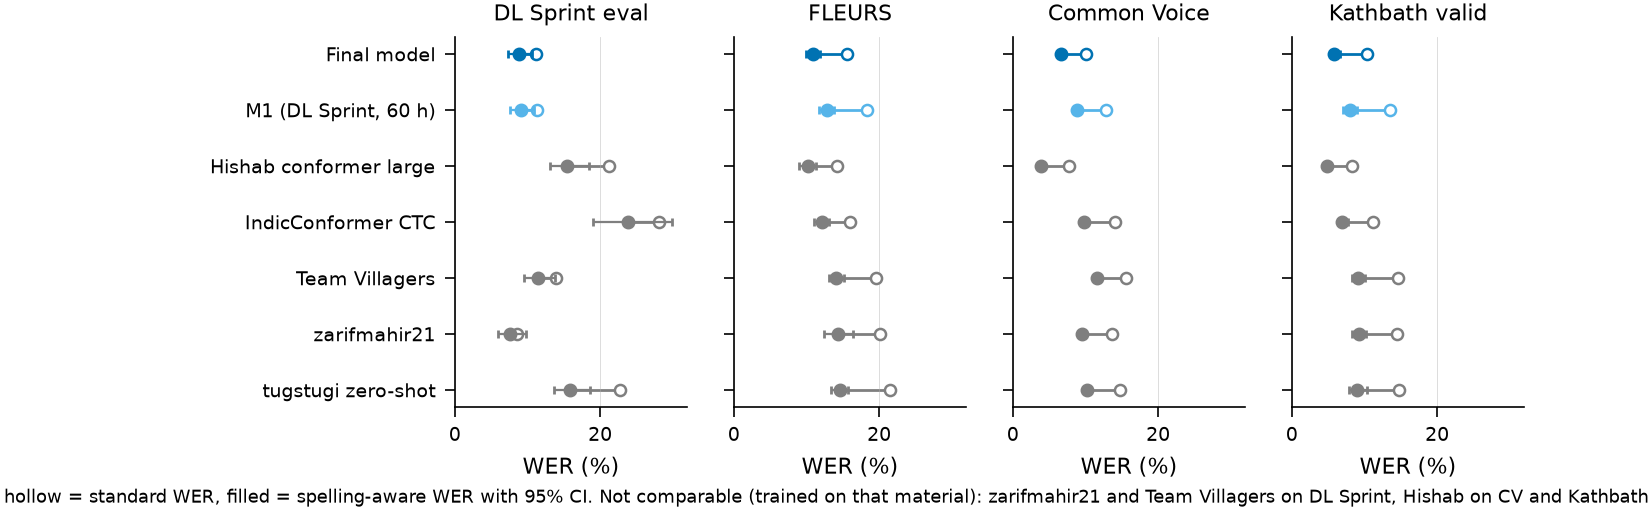

In [4]:
figure("f18_spelling_aware")

Paired differences, final model minus each system (spelling-aware WER, points):

In [5]:
P = pd.read_csv(ROOT / "results/spelling_aware/paired.csv").query("metric == 'sa_wer'")
P["text"] = [f"{100 * d:+.2f} [{100 * lo:+.2f}, {100 * hi:+.2f}]" for d, lo, hi in zip(P.final_minus_system, P.ci_lo, P.ci_hi)]
P.pivot(index="system", columns="set", values="text")[list(SETS)].rename(columns=SETS)

set,DL Sprint eval,FLEURS,Common Voice,Kathbath
system,,,,
Hishab conformer large,"-6.58 [-7.86, -5.47]","+0.73 [+0.01, +1.48]","+2.74 [+2.57, +2.92]","+1.07 [+0.75, +1.43]"
IndicConformer CTC,"-14.98 [-19.53, -11.55]","-1.22 [-1.86, -0.56]","-3.16 [-3.39, -2.96]","-1.10 [-1.40, -0.80]"
IndicConformer RNN-T,"-17.62 [-23.85, -12.81]","-0.50 [-1.15, +0.20]","-2.15 [-2.34, -1.96]","-0.32 [-0.60, +0.00]"
"M1 (DL Sprint, 60 h)","-0.34 [-0.65, -0.04]","-1.89 [-2.37, -1.42]","-2.19 [-2.36, -2.04]","-2.07 [-2.45, -1.71]"
M5 (10 h x 4),"-2.11 [-2.58, -1.76]","-1.09 [-1.62, -0.51]","-0.70 [-0.84, -0.57]","-0.80 [-1.10, -0.55]"
M5-300 (300 h),"-0.25 [-0.37, -0.16]","+0.01 [-0.24, +0.28]","-0.11 [-0.20, -0.02]","-0.03 [-0.17, +0.11]"
M5-full (156 h),"-0.37 [-0.70, -0.14]","-0.42 [-0.73, -0.11]","-0.24 [-0.36, -0.12]","-0.14 [-0.29, +0.01]"
Team Villagers,"-2.57 [-3.15, -2.08]","-3.24 [-3.90, -2.58]","-4.96 [-5.17, -4.76]","-3.26 [-3.71, -2.87]"
tugstugi zero-shot,"-7.00 [-8.01, -6.14]","-3.67 [-4.30, -3.04]","-3.54 [-3.73, -3.36]","-3.15 [-3.88, -2.45]"


**Conclusion:** spelling is 15–50% of every system's errors, the comparisons keep their direction, and about 40% of
the fine-tuning gain on DL Sprint is the corpus's spelling convention; the rest is a real cut in recognition errors.